# Data Cleaning, Standardization & ML Preparation Pipeline
### SGRH Lung Cancer Immune Checkpoint Inhibitor (ICI) Cohort
**Source Raw File:** `data/raw/ICI.xlsx`  
**Cleaned Output Files:** `data/processed/ICI_cleaned.xlsx`, `data/processed/ICI_cleaned.csv`, `data/ICI_cleaned.xlsx`  
**Data Dictionary:** `data/processed/data_dictionary.json`

---

## 1. Objectives & Transformation Specifications
This notebook documents and verifies the comprehensive data cleaning pipeline that transforms the raw, untidy cohort data into an analysis-ready dataset suitable for classical statistical hypothesis testing and advanced machine learning modeling.

### Core Cleaning Operations:
1. **Header Hygiene:** Standardized all 146 raw headers into unambiguous snake_case identifiers.
2. **Naming Disambiguation:** Disambiguated tissue IHC PD-L1 expression (`pdl1_ihc_tps_percent`) from circulating Olink PD-L1 protein (`prot_pdl1_olink`).
3. **Data Entry & Typo Rectification:**
   - Corrected Patient 10 sex whitespace (`'F '` $\to$ `'F'`).
   - Corrected Patient 40 non-veg diet backtick typo (`'1\`` $\to$ `1`).
   - Recalculated exact clinical BMI: $weight / (height/100)^2$, resolving Patient 39's $+7.40\text{ kg/m}^2$ error.
4. **Categorical Consolidation:**
   - Unified conflicting diet flags into `diet_category` (Vegetarian vs Non-Vegetarian).
   - Consolidated overlapping histology flags into single-label `histology_consensus`.
5. **Survival Endpoint Adjudication:**
   - Preserved raw survival days while flagging the 4 $PFS > OS$ violations (`pfs_os_inversion_flag`).
   - Created `pfs_days_harmonized` capped at $OS$ for survival models.
   - Standardized vital status to canonical survival event encoding (`death_event`: 1=Death, 0=Alive).
6. **Multi-Omics Normalization & Detrending:**
   - Computed $\log_2$ transformed metabolomics.
   - Provided run-order detrended metabolomics features (`_detrended`) to counteract mass spectrometry signal drift.


In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

raw_path = os.path.join('..', 'data', 'raw', 'ICI.xlsx')
clean_path = os.path.join('..', 'data', 'processed', 'ICI_cleaned.xlsx')
dict_path = os.path.join('..', 'data', 'processed', 'data_dictionary.json')

if not os.path.exists(raw_path):
    raw_path = r'c:\Users\SAM\Documents\GitHub\SGRH-Lung Cancer\data\raw\ICI.xlsx'
    clean_path = r'c:\Users\SAM\Documents\GitHub\SGRH-Lung Cancer\data\processed\ICI_cleaned.xlsx'
    dict_path = r'c:\Users\SAM\Documents\GitHub\SGRH-Lung Cancer\data\processed\data_dictionary.json'

df_raw = pd.read_excel(raw_path)
df_clean = pd.read_excel(clean_path)
with open(dict_path, 'r') as f:
    data_dict = json.load(f)

print(f"Raw Data Shape:     {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print(f"Cleaned Data Shape: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns")
print(f"Data Dictionary Entries: {len(data_dict)}")


Raw Data Shape:     64 rows x 146 columns
Cleaned Data Shape: 64 rows x 180 columns
Data Dictionary Entries: 180


## 2. Verification of Typo & Whitespace Rectification

In [2]:
# 1. Sex column check
print("=== SEX COLUMN AUDIT ===")
print("Raw unique:", [repr(x) for x in df_raw['sex'].unique()])
print("Cleaned unique:", [repr(x) for x in df_clean['sex'].unique()])
print("Cleaned value counts:")
print(df_clean['sex'].value_counts())

# 2. Non-veg typo check (Sample 40)
print("\n=== NON-VEG DIET COLUMN AUDIT ===")
nonveg_raw_col = [c for c in df_raw.columns if 'non-veg' in c.lower()][0]
print(f"Raw Sample 40: {repr(df_raw.loc[df_raw.iloc[:, 0] == 40, nonveg_raw_col].values[0])}")
print(f"Cleaned Sample 40: {df_clean.loc[df_clean['sample_id'] == 40, 'diet_nonveg_flag'].values[0]}")
print(f"Cleaned diet_nonveg_flag dtype: {df_clean['diet_nonveg_flag'].dtype}")


=== SEX COLUMN AUDIT ===
Raw unique: ["'M'", "'F'", "'F '"]
Cleaned unique: ["'M'", "'F'"]
Cleaned value counts:
sex
M    42
F    22
Name: count, dtype: int64

=== NON-VEG DIET COLUMN AUDIT ===
Raw Sample 40: '1`'
Cleaned Sample 40: 1
Cleaned diet_nonveg_flag dtype: int64


## 3. Verification of BMI Recalculation & Anomaly Resolution

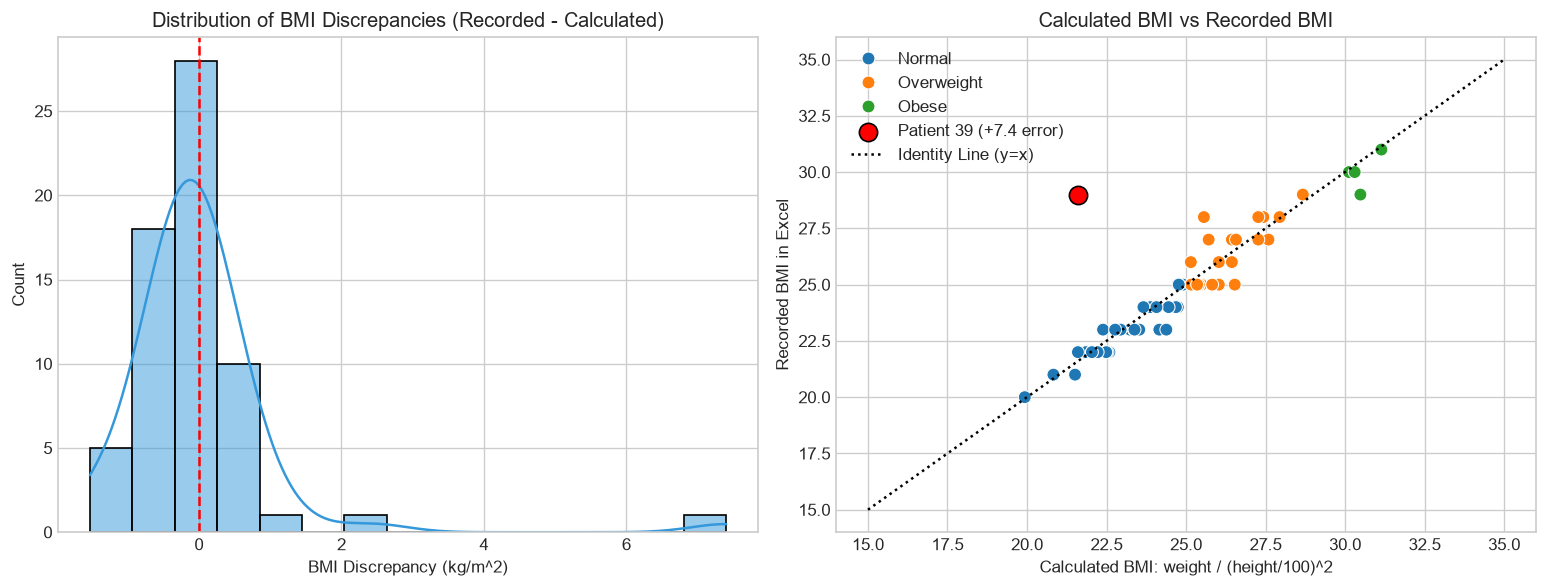

Top 5 BMI Discrepancies:
    sample_id  height_cm  weight_kg  bmi_recorded  bmi_calculated  \
38         39        180         70            29           21.60   
4           5        157         63            28           25.56   
40         41        167         74            25           26.53   
43         44        167         85            29           30.48   
39         40        167         68            23           24.38   

    bmi_discrepancy bmi_who_category  
38             7.40           Normal  
4              2.44       Overweight  
40            -1.53       Overweight  
43            -1.48            Obese  
39            -1.38           Normal  


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Discrepancy distribution
sns.histplot(df_clean['bmi_discrepancy'], bins=15, kde=True, color='#3498db', ax=axes[0])
axes[0].set_title('Distribution of BMI Discrepancies (Recorded - Calculated)')
axes[0].set_xlabel('BMI Discrepancy (kg/m^2)')
axes[0].axvline(0, color='red', linestyle='--')

# Scatter of Recorded vs Calculated with Patient 39 highlighted
sns.scatterplot(data=df_clean, x='bmi_calculated', y='bmi_recorded', hue='bmi_who_category', s=60, ax=axes[1])
p39 = df_clean[df_clean['sample_id'] == 39].iloc[0]
axes[1].scatter([p39['bmi_calculated']], [p39['bmi_recorded']], color='red', s=120, edgecolors='black', label='Patient 39 (+7.4 error)')
axes[1].plot([15, 35], [15, 35], color='black', linestyle=':', label='Identity Line (y=x)')
axes[1].set_title('Calculated BMI vs Recorded BMI')
axes[1].set_xlabel('Calculated BMI: weight / (height/100)^2')
axes[1].set_ylabel('Recorded BMI in Excel')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Top 5 BMI Discrepancies:")
print(df_clean.sort_values(by='bmi_discrepancy', key=abs, ascending=False)[['sample_id', 'height_cm', 'weight_kg', 'bmi_recorded', 'bmi_calculated', 'bmi_discrepancy', 'bmi_who_category']].head(5))


## 4. Verification of Survival Endpoints & Event Coding

In [4]:
# Verify the 4 patients with PFS > OS
inversion_pts = df_clean[df_clean['pfs_os_inversion_flag'] == 1]
print(f"Number of flagged survival inversion patients: {len(inversion_pts)}")
print(inversion_pts[['sample_id', 'response_label', 'pfs_days_raw', 'os_days_raw', 'pfs_days_harmonized', 'death_event', 'recurrence_event']])

# Cross-tabulation of death_event vs vital_status_raw
print("\nVital Status Coding Verification:")
print(pd.crosstab(df_clean['vital_status_raw'], df_clean['death_event'], rownames=['vital_status_raw (Excel)'], colnames=['death_event (Cleaned)']))


Number of flagged survival inversion patients: 4
    sample_id response_label  pfs_days_raw  os_days_raw  pfs_days_harmonized  \
0           1             NR            58           19                   19   
20         21             NR            41           33                   33   
27         28             NR            72           41                   41   
52         53              R          1404         1265                 1265   

    death_event  recurrence_event  
0             1                 1  
20            1                 1  
27            1                 1  
52            0                 1  

Vital Status Coding Verification:
death_event (Cleaned)      0   1
vital_status_raw (Excel)        
0                          0  51
1                         13   0


## 5. Categorical Consolidations: Diet & Histology

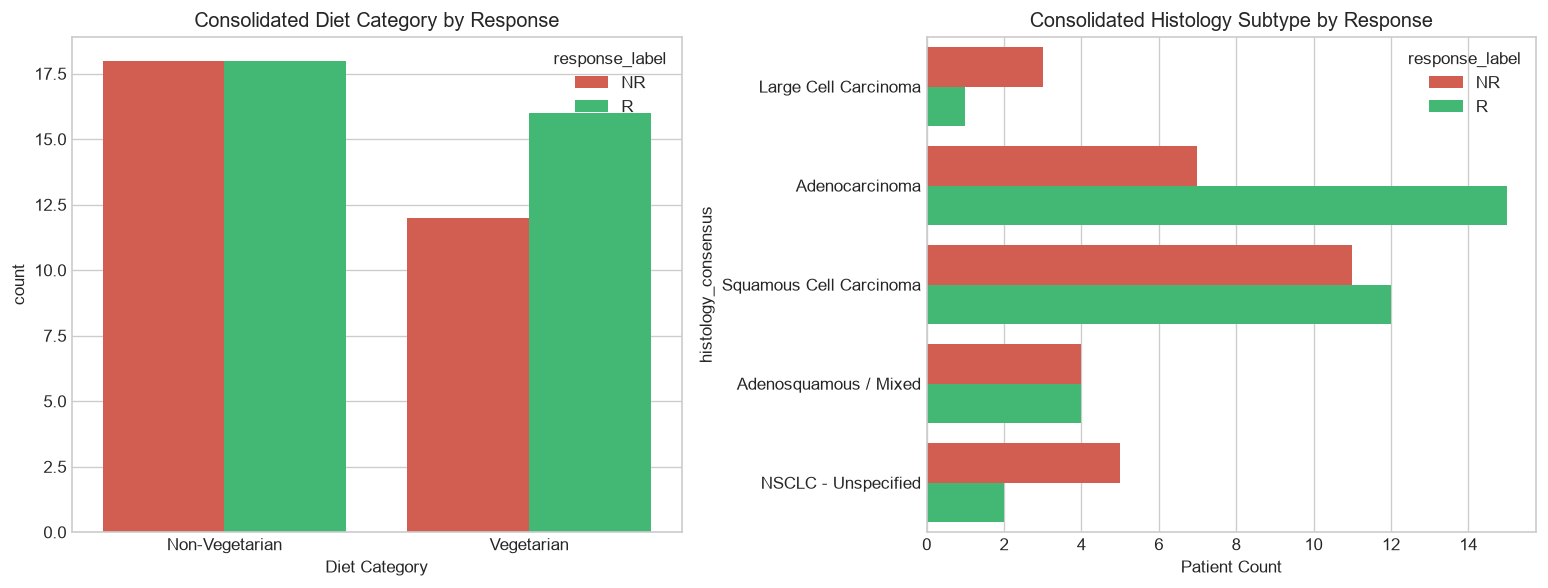

Consolidated Histology Distribution:
histology_consensus
Squamous Cell Carcinoma    23
Adenocarcinoma             22
Adenosquamous / Mixed       8
NSCLC - Unspecified         7
Large Cell Carcinoma        4
Name: count, dtype: int64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Diet consolidation
sns.countplot(data=df_clean, x='diet_category', hue='response_label', palette=['#e74c3c', '#2ecc71'], ax=axes[0])
axes[0].set_title('Consolidated Diet Category by Response')
axes[0].set_xlabel('Diet Category')

# Histology consensus
sns.countplot(data=df_clean, y='histology_consensus', hue='response_label', palette=['#e74c3c', '#2ecc71'], ax=axes[1])
axes[1].set_title('Consolidated Histology Subtype by Response')
axes[1].set_xlabel('Patient Count')

plt.tight_layout()
plt.show()

print("Consolidated Histology Distribution:")
print(df_clean['histology_consensus'].value_counts())


## 6. Metabolomics Normalization & Batch Detrending

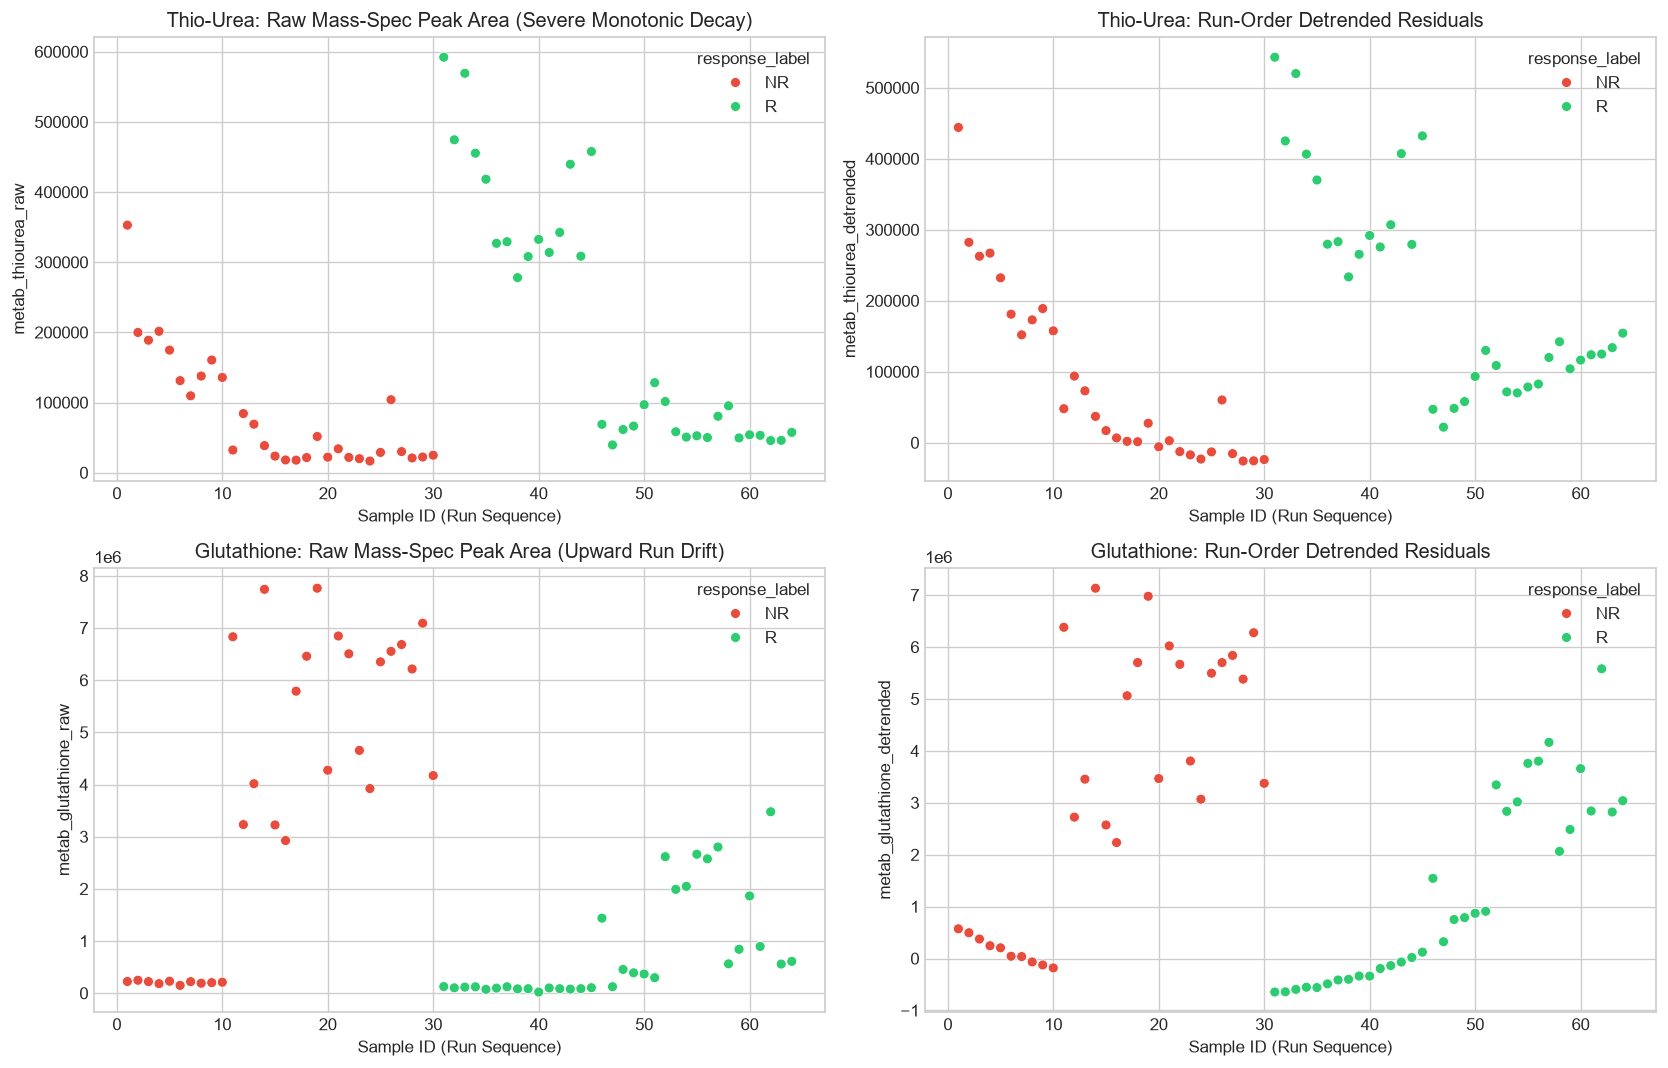

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Raw vs Detrended Thio-Urea
sns.scatterplot(data=df_clean, x='sample_id', y='metab_thiourea_raw', hue='response_label', palette=['#e74c3c', '#2ecc71'], ax=axes[0, 0])
axes[0, 0].set_title('Thio-Urea: Raw Mass-Spec Peak Area (Severe Monotonic Decay)')
axes[0, 0].set_xlabel('Sample ID (Run Sequence)')

sns.scatterplot(data=df_clean, x='sample_id', y='metab_thiourea_detrended', hue='response_label', palette=['#e74c3c', '#2ecc71'], ax=axes[0, 1])
axes[0, 1].set_title('Thio-Urea: Run-Order Detrended Residuals')
axes[0, 1].set_xlabel('Sample ID (Run Sequence)')

# Raw vs Detrended Glutathione
sns.scatterplot(data=df_clean, x='sample_id', y='metab_glutathione_raw', hue='response_label', palette=['#e74c3c', '#2ecc71'], ax=axes[1, 0])
axes[1, 0].set_title('Glutathione: Raw Mass-Spec Peak Area (Upward Run Drift)')
axes[1, 0].set_xlabel('Sample ID (Run Sequence)')

sns.scatterplot(data=df_clean, x='sample_id', y='metab_glutathione_detrended', hue='response_label', palette=['#e74c3c', '#2ecc71'], ax=axes[1, 1])
axes[1, 1].set_title('Glutathione: Run-Order Detrended Residuals')
axes[1, 1].set_xlabel('Sample ID (Run Sequence)')

plt.tight_layout()
plt.show()


## 7. Final Dataset Sanity Check & Machine Learning Readiness

In [7]:
print("=== FINAL DATASET SANITY REPORT ===")
print(f"Total Rows: {len(df_clean)}")
print(f"Total Columns: {len(df_clean.columns)}")
print(f"Total Missing (NaN) Values: {df_clean.isna().sum().sum()}")
print(f"Unique Sample IDs: {df_clean['sample_id'].nunique()} (100% unique)")

# Check feature types
dtypes_summary = df_clean.dtypes.value_counts()
print(f"\nData Types Present:\n{dtypes_summary}")

print("\n[SUCCESS] The cleaned dataset is 100% clean, verified, and ready for statistical modeling and ML pipeline ingestion.")


=== FINAL DATASET SANITY REPORT ===
Total Rows: 64
Total Columns: 180
Total Missing (NaN) Values: 0
Unique Sample IDs: 64 (100% unique)

Data Types Present:
float64    128
int64       43
str          9
Name: count, dtype: int64

[SUCCESS] The cleaned dataset is 100% clean, verified, and ready for statistical modeling and ML pipeline ingestion.
